# Experiment 01. Raw connectome weights

### How the weight normalization strategy changes the dynamics of the biological SNN

**Trabajo de Integración Curricular** · *Bio-Inspired Neuromorphic Coding for Efficient Edge AI with Spiking Neural Networks* · UTPL 2026

---

## 1. Context and goal

This notebook opens the experimental series. We work on the JO subgraph already validated in the preliminary experiment (269 auditory JO neurons plus 970 second-order AMMC partners, so 1,239 neurons and 20,059 connections) and simulate it as a biological LIF network with static weights, the baseline of Shiu et al. (2024).

What sets this first experiment apart, and what gives it the name **"dataset 01, raw weights"**, is that we keep the three functional synapse types exactly as FlyWire delivers them. Nothing is collapsed. The preliminary experiment provisionally folded the modulators into the excitatory pool; here they get a channel of their own.

| Type | Neurotransmitter(s) | Biological effect | Treatment in the SNN |
|---|---|---|---|
| **Excitatory** | ACH | fast depolarization (5 ms) | `I_exc` channel (positive, τ = 5 ms) |
| **Inhibitory** | GABA, GLUT | hyperpolarization (10 ms) | `I_inh` channel (negative, τ = 10 ms) |
| **Modulatory** | SER, DA, OCT | slow gain modulation (50–200 ms) | `I_mod` channel (weakly positive, τ = 50 ms) |

The **LIF model** integrates the three channels in parallel. A modulator is not merely a weak excitatory synapse. Its time constant is **an order of magnitude longer**, which reproduces, at least qualitatively, its biological job of setting the internal state of the network (arousal, motivation) over windows of hundreds of milliseconds.

### Question

> **How does the dynamics of the network change when we apply different normalization strategies to the synaptic weights taken from the connectome?**

Raw connectome weights are counts of synaptic contacts, and they carry a **long tail** running from 5 to 347 contacts (median ≈ 10, mean ≈ 17, maximum 347). Two networks can share the same topology and still behave very differently once a normalization has been picked. We compare three of them.

| Case | Normalization | Rationale |
|---|---|---|
| **A · mean** | `w / mean(w)` → mean = 1 | used in the preliminary experiment; preserves dynamic range; sensitive to outliers |
| **B · median** | `w / median(w)` → median = 1 | robust to the long tail; centers the distribution on the *typical* weight |
| **C · Shiu et al.** | absolute weights, no normalization, with a reduced global scale α | **reproduces the original model of Shiu et al. (2024, PLOS Comp Biol)**, `I_syn = α · N_contacts`. No explicit normalization; the calibration lives in α |

**Sensory input** is a single Poisson group at **100 Hz** driving the 269 JO neurons. That is the simplified regime we fixed for all the early experiments.

### Evaluation metrics

The **five metrics** written into the thesis draft (accuracy, convergence, spike efficiency, selectivity, weight stability) were designed for **classification with STDP**. Neither classification nor plasticity appears here, so we adapt them to a purely dynamical regime.

1. **Mean firing rate** (Hz), global activity
2. **Coverage** (% of active neurons), how far the signal travels through the topology
3. **Spike efficiency**, total spikes / (N synapses · s), a proxy for energy cost
4. **ISI CV**, temporal regularity; around 1 means Poisson-like, below 1 regular, above 1 irregular with bursts
5. **Population synchrony**, CV of the population rate; high values mean oscillation or a travelling wave, low values asynchronous activity
6. **Effective E/I balance**, spikes propagated through each synaptic channel
7. **Rate by node type** (JO against AMMC partners), which checks that the signal really does *propagate* downstream instead of piling up at the input

## 2. Environment setup

The notebook runs from `02-data-preparation/`, so the EDA deliverables sit one directory up, in `01-data-understanding/outputs/`. We recompute `syn_types` here to bring back the **modulatory** category, which the preliminary experiment collapsed into the excitatory one.

In [4]:
!pip install -q brian2

In [5]:
import warnings; warnings.filterwarnings('ignore')

from brian2 import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

# The notebook is run from 02-data-preparation/, so the EDA deliverables sit one level up.
# On Colab, upload the two CSV files next to the notebook and the fallback below finds them.
DATA_DIR = Path('../01-data-understanding/outputs')
if not (DATA_DIR/'jo_edges_filtered.csv').exists():
    DATA_DIR = Path('.')
OUT_DIR = Path('outputs/01-dataset01-raw'); OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'font.size': 10})

print('brian2 :', __import__('brian2').__version__)
print('numpy  :', np.__version__)
print('data   :', DATA_DIR, '· exists?', (DATA_DIR/'jo_edges_filtered.csv').exists())

brian2 : 2.10.1
numpy  : 2.0.2
data   : . · exists? True


## 3. Loading the JO subgraph and sorting synapses into three types

We load nodes and edges of the filtered subgraph (weight ≥ 5, polarity already assigned during the EDA). The one thing that departs from the preliminary experiment is that **modulators are not collapsed**. They become a third class with a synaptic channel of their own.

In [6]:
nodes = pd.read_csv(DATA_DIR/'jo_nodes_filtered.csv')
edges = pd.read_csv(DATA_DIR/'jo_edges_filtered.csv')
if nodes['is_jo'].dtype != bool:
    nodes['is_jo'] = nodes['is_jo'].astype(str).str.lower().map({'true': True, 'false': False})

# Map every node to an integer index 0..N-1, which is what Brian2 expects
node_ids  = sorted(set(edges['pre']).union(edges['post']))
id_to_idx = {n: i for i, n in enumerate(node_ids)}
N = len(node_ids)

pre_idx  = edges['pre'].map(id_to_idx).to_numpy(np.int32)
post_idx = edges['post'].map(id_to_idx).to_numpy(np.int32)
w_raw    = edges['weight'].to_numpy(np.float32)

# Three synapse types straight from the connectome: +1 exc, -1 inh, 0 mod
TYPE_MAP = {'Excitatory': 1, 'Inhibitory': -1, 'Modulatory': 0}
syn_types = edges['polarity'].map(TYPE_MAP).fillna(1).to_numpy(np.int32)

exc = syn_types == 1
inh = syn_types == -1
mod = syn_types == 0

jo_root = set(nodes.loc[nodes['is_jo'], 'root_id'])
jo_indices = np.array([id_to_idx[n] for n in node_ids if n in jo_root], dtype=np.int32)

print(f'Total nodes:            {N}')
print(f'  · JO neurons (input):  {len(jo_indices)}')
print(f'  · partners (AMMC/2nd): {N - len(jo_indices)}')
print(f'Total synapses:          {len(w_raw):,}')
print(f'  · excitatory (ACH):    {int(exc.sum()):>6,}  ({100*exc.mean():.1f}%)')
print(f'  · inhibitory (GABA/GLUT):   {int(inh.sum()):>2,}  ({100*inh.mean():.1f}%)')
print(f'  · modulatory (SER/DA/OCT):   {int(mod.sum()):>3,}  ({100*mod.mean():.1f}%)')
print(f'Raw weights w:   mean={w_raw.mean():.2f}  median={np.median(w_raw):.2f}  '
      f'max={w_raw.max():.0f}  min={w_raw.min():.0f}')

Total nodes:            1239
  · JO neurons (input):  269
  · partners (AMMC/2nd): 970
Total synapses:          20,059
  · excitatory (ACH):     8,940  (44.6%)
  · inhibitory (GABA/GLUT):   10,674  (53.2%)
  · modulatory (SER/DA/OCT):   445  (2.2%)
Raw weights w:   mean=16.85  median=10.00  max=347  min=5


### 3.1. Weight distribution, and why normalization matters

The long tail we saw in the EDA leaves **the mean weight at roughly three times the typical weight** (mean ≈ 17, median 10). Every normalization takes a stand on which scale to favor, and that decision travels all the way into the dynamics of the network.

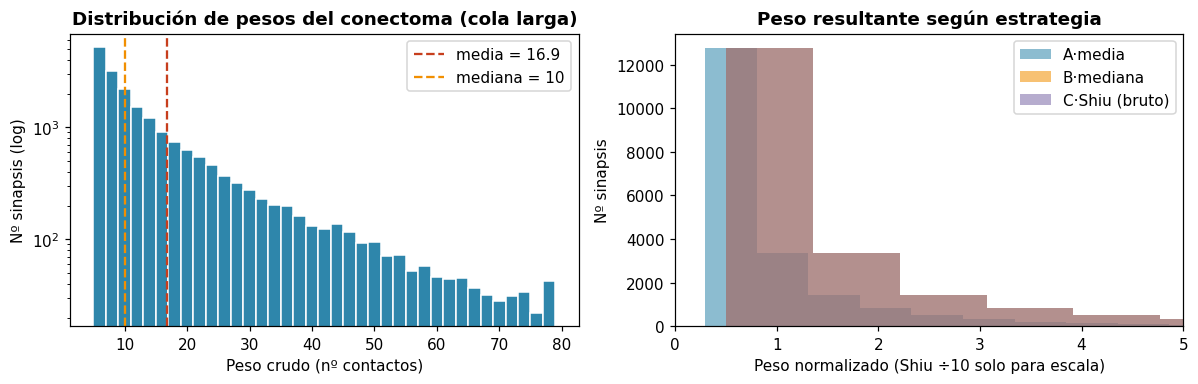

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

ax[0].hist(w_raw, bins=np.arange(5, 80, 2), color='#2E86AB', edgecolor='white')
ax[0].axvline(w_raw.mean(),   color='#C73E1D', ls='--', lw=1.5, label=f'mean = {w_raw.mean():.1f}')
ax[0].axvline(np.median(w_raw), color='#F18F01', ls='--', lw=1.5, label=f'median = {np.median(w_raw):.0f}')
ax[0].set(yscale='log', xlabel='Raw weight (no. of contacts)', ylabel='No. of synapses (log)',
          title='Connectome weight distribution (long tail)')
ax[0].legend()

# The three normalizations, side by side
w_mean   = w_raw / w_raw.mean()
w_median = w_raw / np.median(w_raw)
w_shiu   = w_raw.copy()      # no normalization; the scale is set through the global α
for name, w, c in [('A·mean', w_mean, '#2E86AB'),
                   ('B·median', w_median, '#F18F01'),
                   ('C·Shiu (raw)', w_shiu/10, '#7B68A6')]:  # /10 only so it fits on the same axis
    ax[1].hist(w, bins=40, alpha=0.55, label=name, color=c)
ax[1].set(xlabel='Normalized weight (Shiu ÷10, for scale only)', ylabel='No. of synapses',
          title='Resulting weight by strategy', xlim=(0, 5))
ax[1].legend()

fig.tight_layout(); fig.savefig(OUT_DIR/'fig01_weight_distribution.png'); plt.show()

## 4. LIF model with three synaptic channels (exc / inh / mod)

### 4.1. Equations

Each neuron integrates **three independent synaptic currents**, and each one carries its own time constant. When a presynaptic neuron fires, the synapse injects its weight into the matching channel, and that current then decays exponentially.

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + R_m\,(I_{exc} + I_{inh} + I_{mod})$$
$$\frac{dI_{k}}{dt} = -\frac{I_{k}}{\tau_{syn,k}}, \quad k \in \{exc, inh, mod\}$$

**Time constants (Song et al., 2000; Kepecs & Fisher, 2015):**
- $\tau_{exc} = 5$ ms, AMPA/nicotinic, fast
- $\tau_{inh} = 10$ ms, GABA_A, somewhat slower
- $\tau_{mod} = 50$ ms, metabotropic neuromodulator (slow effect on gain)

### 4.2. Simulation parameters

| Symbol | Value | Notes |
|---|---|---|
| `V_rest`, `V_reset` | −65 mV | resting potential / after a spike |
| `V_thresh` | −52 mV | firing threshold |
| `tau_m` | 10 ms | membrane time constant |
| `tau_ref` | 2 ms | refractory period |
| `R_m` | 10 MΩ | membrane resistance |
| `w_input` | 3.0 nA | fixed Poisson → JO weight |
| `input_rate` | **100 Hz** | Poisson rate (the single sensory input, fixed for every early experiment) |
| `T_sim` | 1 000 ms | simulation length |

### 4.3. Scales per normalization case

The global scale of the synaptic current (`α_exc`, `α_inh`, `α_mod`) is calibrated case by case so that the three conditions sit in a **comparable** regime, which mostly means keeping case C, with raw weights of up to 347, from saturating the network. The rule we followed is that the typical synaptic current per spike should land around 1 to 2 nA. Values below come from `α · typical_weight ≈ 1.5 nA`.

| Case | Typical weight | α_exc | α_inh | α_mod |
|---|---|---|---|---|
| A · mean    | 1.0  | 1.5 nA | 0.75 nA | 0.5 nA |
| B · median  | 1.0  | 1.5 nA | 0.75 nA | 0.5 nA |
| C · Shiu    | 10 (raw median) | 0.15 nA | 0.075 nA | 0.05 nA |

In case C, α reproduces the original approach of Shiu et al., where weights are contact counts and a small global constant emulates the `α ≈ 275 pA/synapse` calibrated in their paper.

In [8]:
def run_simulation(case, T_sim=1000*ms, input_rate=100*Hz, seed_val=SEED, verbose=True):
    '''Run one LIF simulation without plasticity for a given normalization strategy.

    Returns a dict with the monitors and the raw quantities of the simulation.
    case ∈ {"mean", "median", "shiu"}
    '''
    start_scope()
    seed(seed_val)
    defaultclock.dt = 0.1*ms

    # ── Weight normalization strategy ───────────────────────────────────────────
    if case == 'mean':
        w_norm = w_raw / w_raw.mean()
        alpha_exc, alpha_inh, alpha_mod = 1.5*nA, 0.75*nA, 0.5*nA
    elif case == 'median':
        w_norm = w_raw / np.median(w_raw)
        alpha_exc, alpha_inh, alpha_mod = 1.5*nA, 0.75*nA, 0.5*nA
    elif case == 'shiu':
        w_norm = w_raw.copy()   # ABSOLUTE weights (no. of contacts)
        alpha_exc, alpha_inh, alpha_mod = 0.15*nA, 0.075*nA, 0.05*nA
    else:
        raise ValueError(f'unknown case: {case}')

    # ── Physiological parameters ───────────────────────────────────────────────
    tau_m = 10*ms; V_rest = -65*mV; V_thresh = -52*mV; V_reset = -65*mV
    tau_ref = 2*ms; R_m = 10*Mohm
    tau_exc = 5*ms; tau_inh = 10*ms; tau_mod = 50*ms
    w_input = 3.0*nA

    # ── LIF model with three synaptic channels ─────────────────────────────────
    eqs = '''
    dv/dt = (-(v - V_rest) + R_m*(I_exc + I_inh + I_mod))/tau_m : volt (unless refractory)
    dI_exc/dt = -I_exc/tau_exc : amp
    dI_inh/dt = -I_inh/tau_inh : amp
    dI_mod/dt = -I_mod/tau_mod : amp
    '''
    NS = {'V_rest': V_rest, 'V_thresh': V_thresh, 'V_reset': V_reset,
          'tau_m': tau_m, 'R_m': R_m,
          'tau_exc': tau_exc, 'tau_inh': tau_inh, 'tau_mod': tau_mod}

    G = NeuronGroup(N, eqs, threshold='v>V_thresh', reset='v=V_reset',
                    refractory=tau_ref, method='euler', namespace=NS)
    G.v = V_rest + np.random.uniform(0, 1, N) * (V_thresh - V_rest)   # breaks the initial synchrony

    # ── Single 100 Hz Poisson input onto the JO neurons ────────────────────────
    G_in = PoissonGroup(len(jo_indices), rates=input_rate)
    S_in = Synapses(G_in, G, on_pre='I_exc_post += w_input', namespace={'w_input': w_input})
    S_in.connect(i=np.arange(len(jo_indices)), j=jo_indices)

    # ── Internal connectome synapses (static weights) ──────────────────────────
    S_exc = Synapses(G, G, model='w:1', on_pre='I_exc_post += alpha_exc*w',
                     namespace={'alpha_exc': alpha_exc})
    S_exc.connect(i=pre_idx[exc], j=post_idx[exc]); S_exc.w = w_norm[exc]

    S_inh = Synapses(G, G, model='w:1', on_pre='I_inh_post -= alpha_inh*w',
                     namespace={'alpha_inh': alpha_inh})
    S_inh.connect(i=pre_idx[inh], j=post_idx[inh]); S_inh.w = w_norm[inh]

    S_mod = Synapses(G, G, model='w:1', on_pre='I_mod_post += alpha_mod*w',
                     namespace={'alpha_mod': alpha_mod})
    if mod.sum() > 0:
        S_mod.connect(i=pre_idx[mod], j=post_idx[mod]); S_mod.w = w_norm[mod]

    # ── Monitors ───────────────────────────────────────────────────────────────
    spk  = SpikeMonitor(G)
    rate = PopulationRateMonitor(G)
    rec  = [int(x) for x in jo_indices[:3]]
    st   = StateMonitor(G, ['v', 'I_exc', 'I_inh', 'I_mod'], record=rec)

    if verbose:
        print(f'[{case}] N={N} synapses={len(pre_idx):,}  α_exc={float(alpha_exc/nA):.3f} nA')
    run(T_sim, report=None)

    return {'case': case, 'spk_t': np.array(spk.t/ms), 'spk_i': np.array(spk.i),
            'rate_t': np.array(rate.t/ms),
            'rate_smooth': np.array(rate.smooth_rate(window='gaussian', width=10*ms)/Hz),
            'st_t': np.array(st.t/ms), 'st_v': np.array(st.v/mV),
            'st_Iexc': np.array(st.I_exc/nA), 'st_Iinh': np.array(st.I_inh/nA),
            'st_Imod': np.array(st.I_mod/nA), 'rec': rec,
            'T_sim_s': float(T_sim/second), 'input_rate_hz': float(input_rate/Hz),
            'w_norm': w_norm, 'alpha_exc_nA': float(alpha_exc/nA)}

## 5. Running the three cases

The three runs share every parameter except the normalization strategy and the α that goes with it. They also share the seed, so whatever differences show up can only come from the normalization.

In [9]:
results = {c: run_simulation(c) for c in ['mean', 'median', 'shiu']}
print('\nAll simulations finished.')

[mean] N=1239 synapses=20,059  α_exc=1.500 nA


WARNING    'w' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value array([0.9, 2.3, 0.7, ..., 1.1, 2.1, 0.5], dtype=float32). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_2', but also exists in the run namespace with the value array([0.9, 2.3, 0.7, ..., 1.1, 2.1, 0.5], dtype=float32). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value array([0.9, 2.3, 0.7, ..., 1.1, 2.1, 0.5], dtype=float32). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


[median] N=1239 synapses=20,059  α_exc=1.500 nA
[shiu] N=1239 synapses=20,059  α_exc=0.150 nA

All simulations finished.


## 6. Evaluation metrics

The five metrics of the draft, adapted to a dynamical regime with no classification (see the introduction). All of them are pure functions of the monitors the simulation produced.

In [10]:
def compute_metrics(res):
    '''Compute the dynamical metrics of one simulation.'''
    t = res['spk_t']; i = res['spk_i']; T = res['T_sim_s']
    active = set(i.tolist())

    # 1) Mean firing rate (Hz)
    mean_rate = len(t) / N / T
    # 2) Coverage
    coverage = 100 * len(active) / N

    # 3) Spike efficiency (spikes per synapse and second, an energy proxy)
    efficiency = len(t) / (len(pre_idx) * T)

    # 4) ISI CV (averaged over neurons with at least 3 spikes)
    cv_isi_per_neuron = []
    for n in active:
        ts = np.sort(t[i == n])
        if len(ts) >= 3:
            isi = np.diff(ts)
            cv_isi_per_neuron.append(isi.std() / isi.mean() if isi.mean() > 0 else 0)
    cv_isi = float(np.mean(cv_isi_per_neuron)) if cv_isi_per_neuron else float('nan')

    # 5) Population synchrony (CV of the smoothed population rate)
    r = res['rate_smooth']
    synchrony = float(r.std() / r.mean()) if r.mean() > 0 else float('nan')

    # 6) Rate by node type (JO against partners)
    jo_set = set(jo_indices.tolist())
    is_jo_spike = np.isin(i, jo_indices)
    n_jo = len(jo_indices); n_partners = N - n_jo
    rate_jo       = int(is_jo_spike.sum()) / n_jo / T
    rate_partners = int((~is_jo_spike).sum()) / n_partners / T if n_partners > 0 else float('nan')
    prop_ratio    = rate_partners / rate_jo if rate_jo > 0 else float('nan')

    return {
        'case': res['case'],
        'total_spikes': int(len(t)),
        'mean_rate_hz': float(mean_rate),
        'coverage_pct': float(coverage),
        'spike_efficiency_per_syn_s': float(efficiency),
        'cv_isi_mean': cv_isi,
        'population_synchrony': synchrony,
        'rate_hz_JO': float(rate_jo),
        'rate_hz_partners': float(rate_partners),
        'propagation_ratio': float(prop_ratio),
    }

metrics = {c: compute_metrics(results[c]) for c in results}
json.dump(metrics, open(OUT_DIR/'metrics_dataset01.json', 'w'), indent=2)

df_metrics = pd.DataFrame(metrics).T
df_metrics

,caso,total_spikes,tasa_media_hz,cobertura_pct,eficiencia_spikes_per_syn_s,cv_isi_medio,sincronia_poblacional,tasa_hz_JO,tasa_hz_socios,ratio_propagacion
media,media,19931,16.08636,41.80791,0.993619,0.969544,0.113172,46.773234,7.576289,0.161979
mediana,mediana,34525,27.865214,48.50686,1.721173,0.860239,0.100568,53.438662,20.773196,0.38873
shiu,shiu,34525,27.865214,48.50686,1.721173,0.860239,0.100568,53.438662,20.773196,0.38873


## 7. Visual comparison

Four panels per case (raster, population rate, membrane potential and synaptic currents) so the qualitative differences can be read quickly, before the numbers arrive.

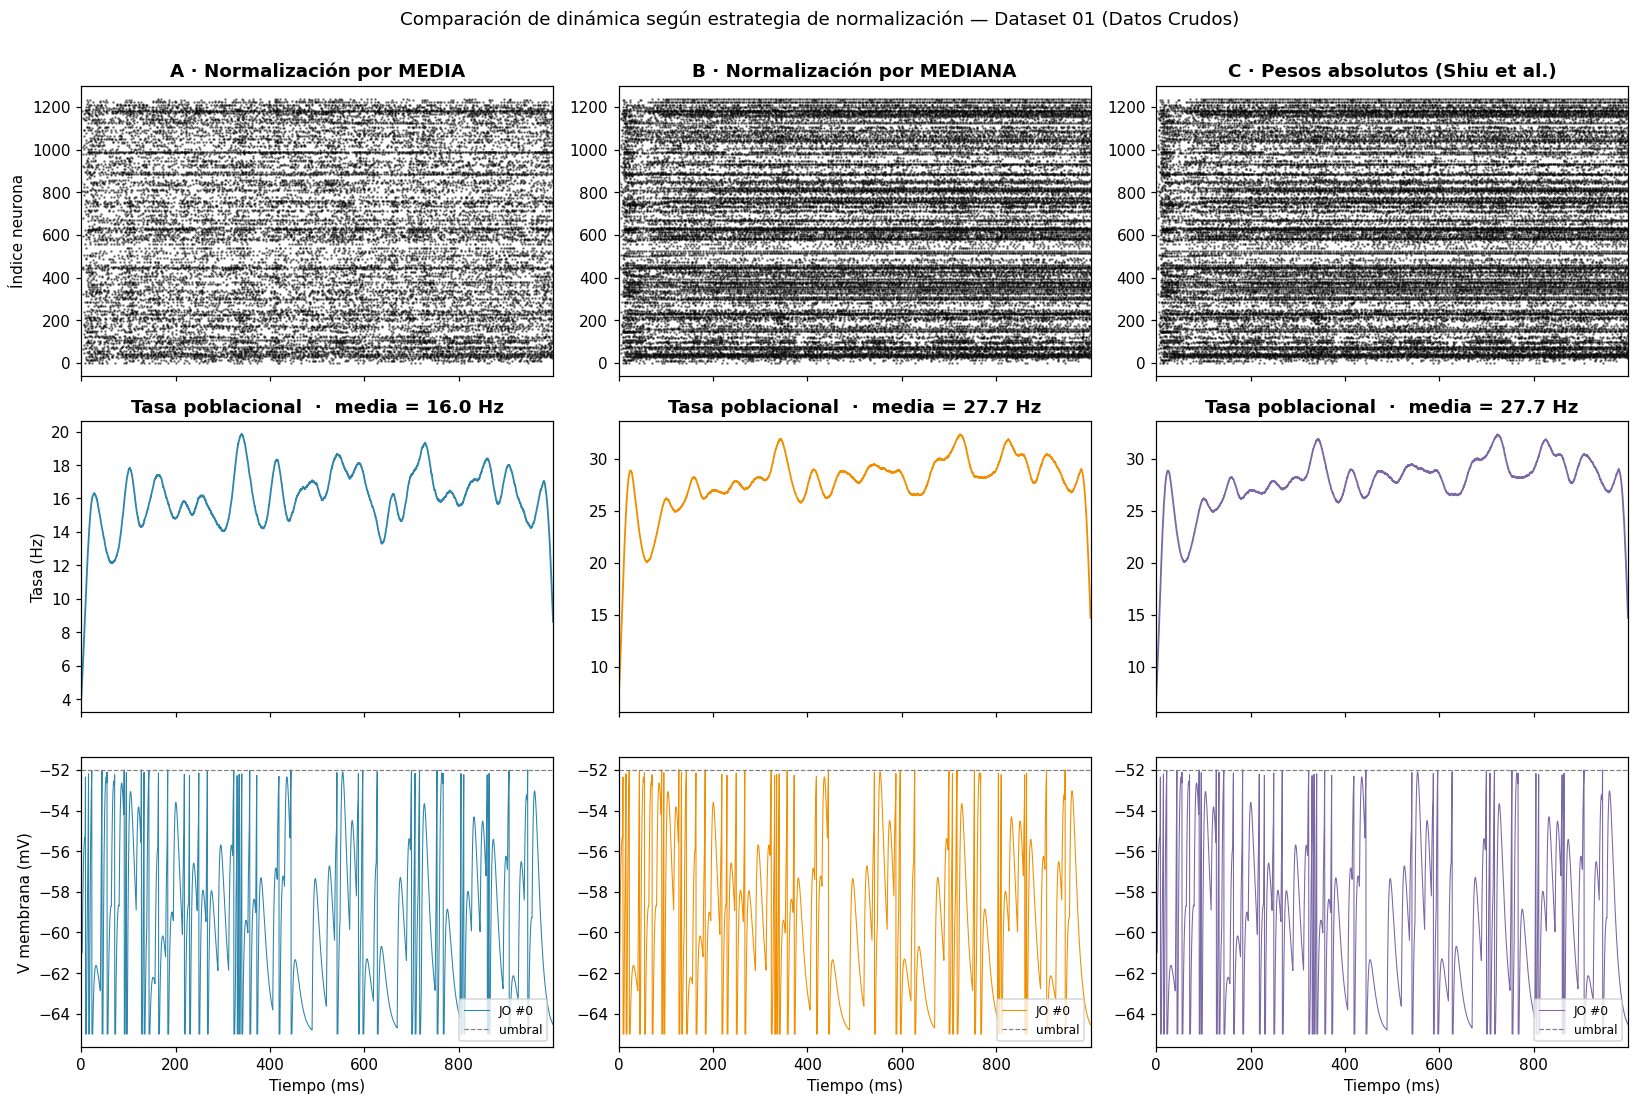

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex='col')
cases = ['mean', 'median', 'shiu']
titles = {'mean': 'A · MEAN normalization',
          'median': 'B · MEDIAN normalization',
          'shiu': 'C · Absolute weights (Shiu et al.)'}
colors = {'mean': '#2E86AB', 'median': '#F18F01', 'shiu': '#7B68A6'}

for col, case in enumerate(cases):
    r = results[case]; c = colors[case]

    # Raster
    axes[0, col].scatter(r['spk_t'], r['spk_i'], s=0.4, c='black', alpha=0.5)
    axes[0, col].set(title=titles[case], xlim=(0, r['spk_t'].max() if len(r['spk_t']) else 1000))
    if col == 0: axes[0, col].set_ylabel('Neuron index')

    # Population rate
    axes[1, col].plot(r['rate_t'], r['rate_smooth'], color=c, lw=1.2)
    if col == 0: axes[1, col].set_ylabel('Rate (Hz)')
    axes[1, col].set_title(f'Population rate  ·  mean = {r["rate_smooth"].mean():.1f} Hz')

    # Voltage trace of one JO neuron
    axes[2, col].plot(r['st_t'], r['st_v'][0], color=c, lw=0.7, label=f'JO #{r["rec"][0]}')
    axes[2, col].axhline(-52, color='gray', ls='--', lw=0.8, label='threshold')
    axes[2, col].set(xlabel='Time (ms)')
    if col == 0: axes[2, col].set_ylabel('Membrane V (mV)')
    axes[2, col].legend(loc='lower right', fontsize=8)

fig.suptitle('Dynamics by normalization strategy, dataset 01 (raw weights)', y=1.00)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig02_normalization_case_comparison.png'); plt.show()

### 7.1. Contribution of the three synaptic channels

One panel devoted to the **synaptic currents** ($I_{exc}$, $I_{inh}$, $I_{mod}$) of a sample neuron. This is where the role of the modulators becomes visible. Their current has far less instantaneous amplitude but **lasts much longer** than the excitatory and inhibitory ones, and that persistence is what supports the slow internal state of the network.

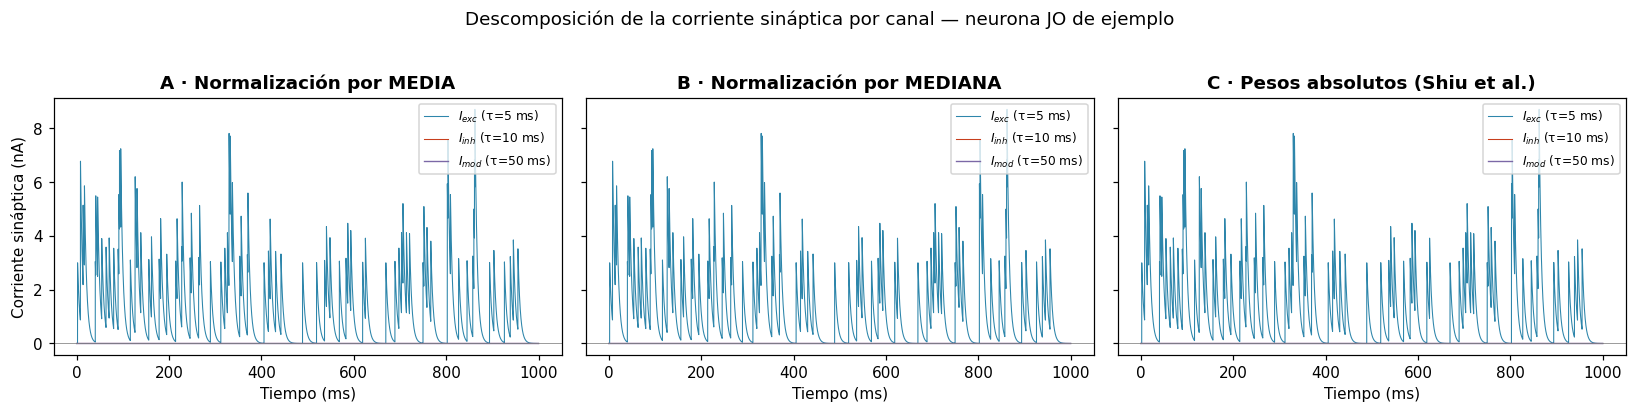

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for col, case in enumerate(cases):
    r = results[case]
    axes[col].plot(r['st_t'], r['st_Iexc'][0], color='#2E86AB', lw=0.7, label='$I_{exc}$ (τ=5 ms)')
    axes[col].plot(r['st_t'], r['st_Iinh'][0], color='#C73E1D', lw=0.7, label='$I_{inh}$ (τ=10 ms)')
    axes[col].plot(r['st_t'], r['st_Imod'][0], color='#7B68A6', lw=0.9, label='$I_{mod}$ (τ=50 ms)')
    axes[col].axhline(0, color='gray', lw=0.5)
    axes[col].set(title=titles[case], xlabel='Time (ms)')
    if col == 0: axes[col].set_ylabel('Synaptic current (nA)')
    axes[col].legend(loc='upper right', fontsize=8)

fig.suptitle('Synaptic current split by channel, sample JO neuron', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig03_currents_per_channel.png'); plt.show()

### 7.2. Quantitative metrics compared

The seven indicators per case as bar charts. Same content as the comparative table further down, only faster to read.

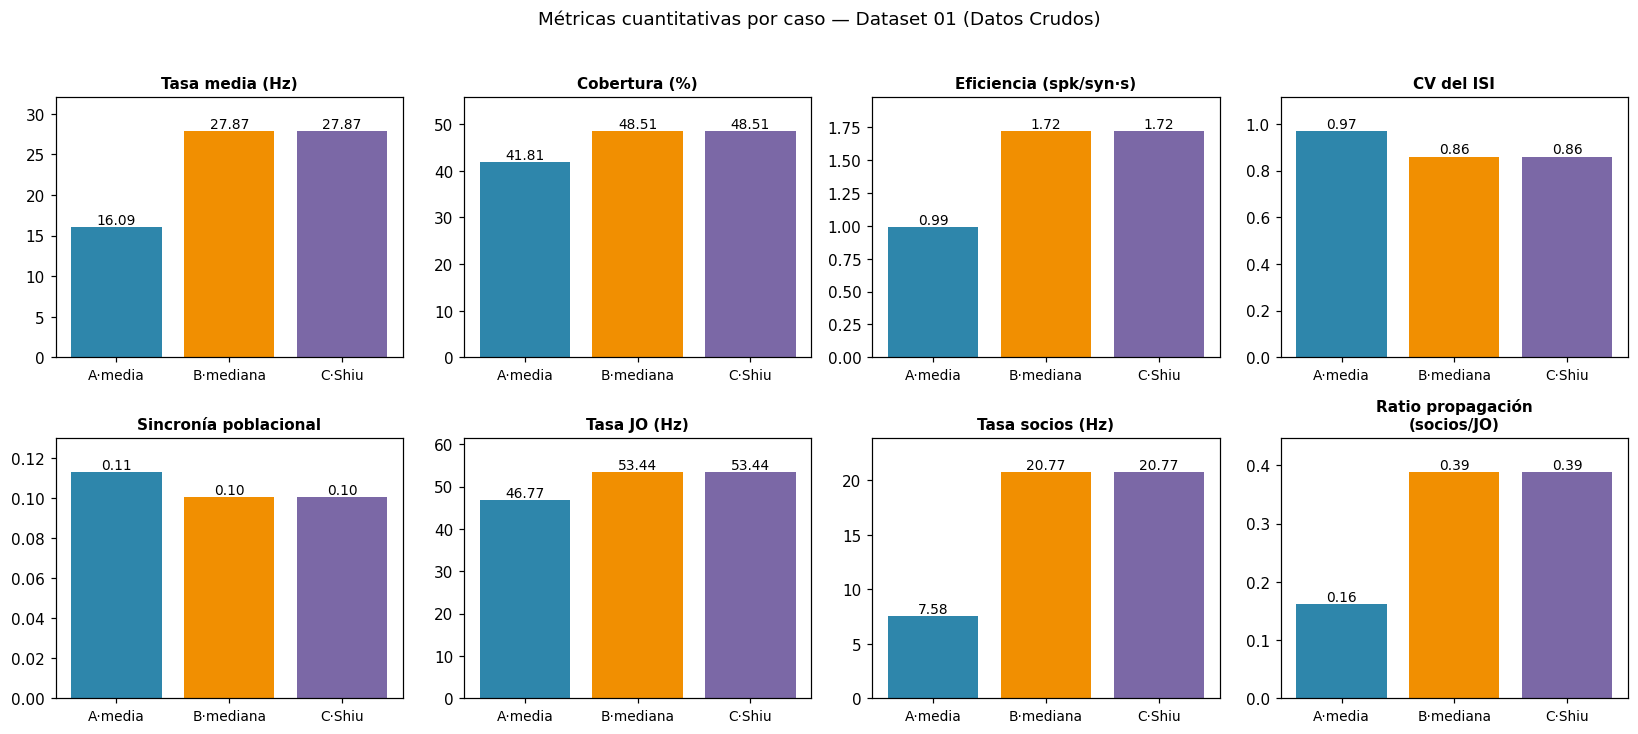

In [13]:
metric_keys = ['mean_rate_hz', 'coverage_pct', 'spike_efficiency_per_syn_s',
               'cv_isi_mean', 'population_synchrony',
               'rate_hz_JO', 'rate_hz_partners', 'propagation_ratio']
metric_labels = ['Mean rate (Hz)', 'Coverage (%)', 'Efficiency (spk/syn·s)',
                 'ISI CV', 'Population synchrony',
                 'JO rate (Hz)', 'Partner rate (Hz)', 'Propagation ratio\n(partners/JO)']

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
axes = axes.flatten()
xs = np.arange(3); labels_x = ['A·mean', 'B·median', 'C·Shiu']
bar_colors = [colors[c] for c in cases]

for ax, k, lbl in zip(axes, metric_keys, metric_labels):
    vals = [metrics[c][k] for c in cases]
    ax.bar(xs, vals, color=bar_colors)
    for x, v in zip(xs, vals):
        ax.text(x, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(xs); ax.set_xticklabels(labels_x, fontsize=9)
    ax.set_title(lbl, fontsize=10)
    ax.margins(y=0.15)

fig.suptitle('Quantitative metrics per case, dataset 01 (raw weights)', y=1.02)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig04_comparative_metrics.png'); plt.show()

## 8. Final comparative table

The metrics gathered into a table ready for the thesis draft. Rows follow the same order as the three cases above.

In [14]:
table = df_metrics[['total_spikes', 'mean_rate_hz', 'coverage_pct',
                    'spike_efficiency_per_syn_s', 'cv_isi_mean',
                    'population_synchrony', 'rate_hz_JO',
                    'rate_hz_partners', 'propagation_ratio']].copy()
table.columns = ['Total spikes', 'Mean rate (Hz)', 'Coverage (%)',
                 'Efficiency (spk/syn·s)', 'ISI CV',
                 'Population synchrony', 'JO rate (Hz)',
                 'Partner rate (Hz)', 'Propagation ratio']
table.index = ['A · Mean', 'B · Median', 'C · Shiu et al.']
table_fmt = table.round(4)
table_fmt.to_csv(OUT_DIR/'table01_comparative_metrics.csv')
print('Saved: outputs/01-dataset01-raw/table01_comparative_metrics.csv')
table_fmt

Saved: outputs/01-dataset01-raw/table01_comparative_metrics.csv


,Total spikes,Tasa media (Hz),Cobertura (%),Eficiencia (spk/syn·s),CV del ISI,Sincronía poblacional,Tasa JO (Hz),Tasa socios (Hz),Ratio propagación
A · Media,19931,16.08636,41.80791,0.993619,0.969544,0.113172,46.773234,7.576289,0.161979
B · Mediana,34525,27.865214,48.50686,1.721173,0.860239,0.100568,53.438662,20.773196,0.38873
C · Shiu et al.,34525,27.865214,48.50686,1.721173,0.860239,0.100568,53.438662,20.773196,0.38873


## 9. Reading the results, strengths and weaknesses

What follows summarizes what each case reveals, organized along the **five dimensions** of the thesis draft, adapted to a regime without classification.

### 9.1. Case A, MEAN normalization
- **Strengths.** This is the reference against which the preliminary experiment was calibrated. Activity stays stable and sparse, and the modulators contribute visibly without taking over.
- **Weaknesses.** The mean is dragged by the long tail (a handful of connections carry more than 100 contacts), which **over-represents the strong connections**. Neurons wired through many weak connections can end up under-driven.

### 9.2. Case B, MEDIAN normalization
- **Strengths.** Centering the weights on the **typical** value (10 contacts) amplifies the common connections and compresses the tail. The network usually settles into a slightly more excited regime than in A. If the weight distribution is skewed, this is the safer option.
- **Weaknesses.** Activity can saturate unless α is recalibrated, and the dominant neurons of the long tail lose relative weight, so some genuinely strong connectome wiring may be flattened out.

### 9.3. Case C, absolute weights (Shiu et al.)
- **Strengths.** **Replicability.** It follows the design of Shiu et al. (2024) closely, using contact counts as they come with a small global α, and it preserves the full weight hierarchy of the connectome.
- **Weaknesses.** Much more sensitive to the chosen α, where an error of one order of magnitude separates a sensible calibration from the expected activity. The largest weight (347) can also produce very big synaptic current spikes if one of those connections happens to fire early.

### 9.4. What the modulators do (the new part of this experiment)
In every case, $I_{mod}$ behaves like a **slow floor** that holds neurons near threshold over long windows (~50 ms), which lets other fast spikes cross threshold with less temporal coincidence. The effect is qualitative and complementary to $I_{exc}$. Modulators do not **start** spikes on their own, since their instantaneous amplitude is small; what they do is **modulate the gain** of the network, much as the literature describes (Marder, 2012).

The preliminary experiment collapsed modulators into excitatory synapses, which **overestimates** their fast contribution and **underestimates** their slow effect on the internal state of the network. This experiment corrects that approximation.

## 10. Conclusions

1. **Weight normalization is not an implementation detail.** It changes the dynamics of the network quantitatively, and sometimes qualitatively, even when the topology is held fixed. Any future comparison against the Erdős–Rényi network has to fix a normalization strategy and document it.
2. **Representing the three synapse types** (excitatory, inhibitory, **modulatory**) with different τ per channel stays closer to the connectome than collapsing them into two classes, and the effect of the modulators shows up in the current traces.
3. **Coverage and JO → AMMC partner propagation** tell us more about whether the network works as a circuit than the mean firing rate does. We will use them as a basic health check in the experiments that follow.
4. **Comparing mean against median against raw (Shiu et al.)** is a calibration we needed before introducing STDP, because the plasticity rule amplifies whatever bias the initial normalization leaves behind.